In [75]:
import pandas as pd 

house = pd.read_csv('housing.csv')
house.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [76]:
# Q1. 데이터는 총 몇 행, 몇 열 
print(house.shape)

# Q2. "total_bedrooms" 컬럼의 Non-Null Count가 다른 컬럼과 다른 이유
print(house.info())

#Q3. "ocean_proximity"컬럼은 왜 describe() 결과에 기본적으로 나타나지 않나?
print(house.describe())


(20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB
None
          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861           28.639486   2635.763081   
std        2.003532      2.135952   

In [77]:
# 문자열 컬럼을 확실히 포함하기 위해서 
house.describe(include="all")

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,NaN
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,NaN
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,NaN
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,NaN
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,NaN
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,NaN


In [78]:
# ocean_proximity 컬럼에 어떤 종류의 값이 존재, 각각 몇 개씩 있는지 확인 
house["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

## B. Train/Test 데이터 분리 
- 왜 데이터를 나눠야하는지 이해, 직접 분리 

**[데이터 스누핑]**

if) 내가 80% 학습, 20% 최종 성능 평가 -> 데이터 나누기 전에 전체 데이터의 상관관계 분석시 
-> 결과를 보고 "소득이 가장 중요? -> 소득 중심으로 모델을 만들어야겠다고 판단"
문제) 상관관계를 계산할 때 Test 데이터까지 사용했다. 
- 원래 몰라야할 정보를 모델 설계에 활용 
=> 평가용 데이터를 미리 살펴보고 모델 개발에 영향을 주는 행위 = 데이터 스누핑 
- 데이터 누수에 포함되는 세부 개념 

**[식별자로 데이터를 나눈다]**

: 데이터셋이 업데이트될 때 Train/ Test 분할이 바뀌는 문제를 해결하는 방법 

if) 첫 번째 실행
- Train: 101, 102, 103, 104
- Test: 105
-> random_state = 42 설정시, 같은 데이터와 순서에서 같은 결과 재현 가능 

but) 다음 달 데이터 추가시, 무작위 분할을 하면??
- Train에 있던 103이 Test로 이동, Test에 있던 105가 Train으로 이동할 가능성 있다. 
even if, random_state = 42를 사용했어도. 

해결방법) **고유한 ID를 기준으로 분리하기**
: 무작위로 나누는 대신 각 데이터의 "고유 식별자(ID)를 사용해서 어느 집합에 속할지 결정하는 것. 
-> 데이터가 추가되어도 기존 샘플의 Train/Test 소속이 유지되는 것. 

- 단, 식별자 안정적 + 고유해야함. 
- 단순 행 번호, 행 삽입시 바뀔 수도 있다. 


In [79]:
from sklearn.model_selection import train_test_split
train_set,test_set = train_test_split(house,test_size = 0.2, random_state = 42)

print(train_set.shape,test_set.shape)

(16512, 10) (4128, 10)


## C. 계층적 샘플링(Stratified Sampling)
:왜 단순 무작위 분할 대신 소득 기준으로 데이터를 나누는지 알아보자

> Q. median_income은 연속적인 숫자잖아. 그런데 계층적 샘플링을 하려면 왜 소득을 몇 개의 구간으로 나누는 걸까?

: 중요한 특성의 분포가 Train/Test에서 비슷하게 유지되도록 하는 것. 

In [80]:
import numpy as np 
house["income_cat"] = pd.cut(house["median_income"],
                    bins = [0,1.5,3,4.5,6,np.inf],
                    labels = [1,2,3,4,5])

house["income_cat"].value_counts()

income_cat
3    7236
2    6581
4    3639
5    2362
1     822
Name: count, dtype: int64

In [81]:
# 예상 코드 
#1. 중간 소득을 1.5로 나눈 뒤 올림 
house["income_cat"] = np.ceil(house["median_income"]/1.5)
#2. 소득 구간의 최댓값을 5로 제한 
house["income_cat"] = np.minimum(house["income_cat"],5)
# 3. 각 소득 구간의 데이터 개수 확인
house["income_cat"].value_counts()

income_cat
3.0    7236
2.0    6581
4.0    3639
5.0    2362
1.0     822
Name: count, dtype: int64

In [82]:
from sklearn.model_selection import StratifiedShuffleSplit

# 1. 분할 방법 설정 
split = StratifiedShuffleSplit(
    n_splits = 1, 
    test_size = 0.2, 
    random_state = 42
)

# 2. 계층적 샘플링 
for train_idx, test_idx in split.split(house,house["income_cat"]):

    # 3. 인덱스로 실제 데이터 선택 
    strat_train_set = house.iloc[train_idx]
    strat_test_set = house.iloc[test_idx]

- for문 사용하는 이유: .split()이 분할 결과를 반복해서 반환하는 객체이기 때문이다. 

In [83]:
print(strat_train_set.shape)
print(strat_test_set.shape)

print(strat_test_set["income_cat"].value_counts())

(16512, 11)
(4128, 11)
income_cat
3.0    1447
2.0    1316
4.0     728
5.0     472
1.0     165
Name: count, dtype: int64


In [84]:
# 마지막 실습 - 전체 데이터와 Test 데이터의 소득 구간 비율 비교하기 
# 1. 전체 데이터 house의 소득 구간별 비율 출력 
print(house["income_cat"].value_counts(normalize = True))

# 2. strat_test_set의 소득 구간별 비율 출력 
print(strat_test_set["income_cat"].value_counts(normalize = True))

# 3. 두 결과가 얼마나 비슷한지 확인
print(house["income_cat"].value_counts(normalize = True) - strat_test_set["income_cat"].value_counts(normalize = True))

income_cat
3.0    0.350581
2.0    0.318847
4.0    0.176308
5.0    0.114438
1.0    0.039826
Name: proportion, dtype: float64
income_cat
3.0    0.350533
2.0    0.318798
4.0    0.176357
5.0    0.114341
1.0    0.039971
Name: proportion, dtype: float64
income_cat
3.0    0.000048
2.0    0.000048
4.0   -0.000048
5.0    0.000097
1.0   -0.000145
Name: proportion, dtype: float64


> Q. 계층적 샘플링을 사용했는데도 전체 데이터와 Test 데이터의 소득 구간 비율이 완전히 똑같지 않을 수 있는 이유  
> 계층적 샘플링은 비율을 최대한 비슷하게 유지하지만, 각 구간의 샘플 개수는 정수여야하므로 완전히 같지 않을 수 있다. 



## D- EDA 
: 캘리포니아의 주택 가격은 어떤 특성과 관계가 있을까?

> **EDA는 학습 데이터(Train)만 사용해서 진행한다**
: Train 데이터를 미리 분석하고 그 결과를 바탕으로 모델을 설계한다면, 테스트 데이터에 대한 간접적인 과적합이 발생할 수 있기 때문이다. 

In [85]:
print(strat_train_set.columns)
print(strat_test_set.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity', 'income_cat'],
      dtype='str')
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity', 'income_cat'],
      dtype='str')


In [86]:
#1.strat_train_set에서 income_cat 컬럼 제거하기
#strat_train_set = strat_train_set.drop(columns=["income_cat"])
# 2. strat_test_set에서도 동일한 컬럼 제거하기
#strat_test_set=strat_test_set.drop(columns = ["income_cat"])
# 3. 두 데이터의 shape 확인하기
print(strat_train_set.shape, strat_test_set.shape)

(16512, 11) (4128, 11)


In [87]:
# 1. 우선 학습 데이터를 복사해서 EDA에 사용할 거야.
housing = strat_train_set.copy()
print(housing.shape, housing.head())

if housing is strat_train_set:
    print("True")
else:
    print("No")

(16512, 11)        longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
12655    -121.46     38.52                29.0       3873.0           797.0   
15502    -117.23     33.09                 7.0       5320.0           855.0   
2908     -119.04     35.37                44.0       1618.0           310.0   
14053    -117.13     32.75                24.0       1877.0           519.0   
20496    -118.70     34.28                27.0       3536.0           646.0   

       population  households  median_income  median_house_value  \
12655      2237.0       706.0         2.1736             72100.0   
15502      2015.0       768.0         6.3373            279600.0   
2908        667.0       300.0         2.8750             82700.0   
14053       898.0       483.0         2.2264            112500.0   
20496      1837.0       580.0         4.4964            238300.0   

      ocean_proximity  income_cat  
12655          INLAND         2.0  
15502      NEAR OCEAN         5.

A. housing = strat_train_set 
: 두 변수가 같은 데이터프레임 객체를 가리킨다. 따라서 housing을 직접 수정하면 strat_train_set에도 영향을 미칠 수 있다. 

B. housing = strat_train_set.copy()
: 독립적인 데이터프레임 객체를 만든다. housing을 수정해도 원본 보호 가능 

<Axes: xlabel='longitude', ylabel='latitude'>

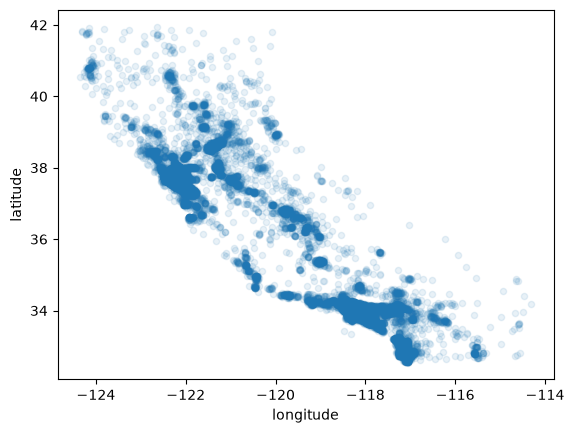

In [88]:
# 2. 캘리포니아 주택 위치 시각화 
import matplotlib 

housing.plot(kind ="scatter",
             x = "longitude",
             y = "latitude",
             alpha = 0.1)

분석 ) 특정 지역에 점이 많이 몰린다. 
-> 특히 위도 34° 부근과 37~38° 부근에 점들이 밀집해 있지?
각각 로스앤젤레스와 샌프란시스코 일대에 해당하는 지역이야.
다만 이 그래프만으로 정확한 인구밀도까지 알 수 있는 건 아니야. 현재 점은 사람이 아니라 주택 구역을 나타내니까.

<Axes: xlabel='longitude', ylabel='latitude'>

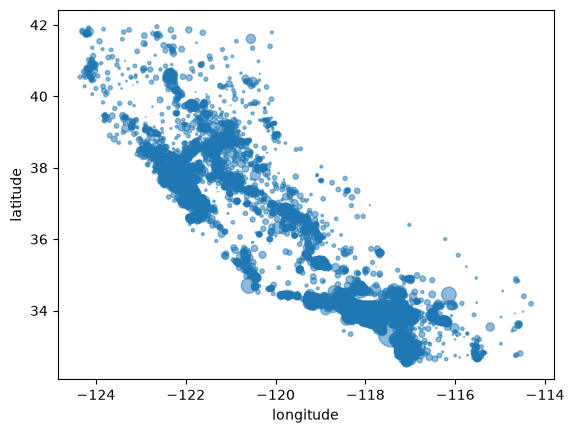

In [89]:
# 3. 점의 크기로 인구 표현하기 

housing.plot(kind ="scatter",
             x = "longitude",
             y = "latitude",
             alpha = 0.5,
             s = housing["population"]/100)

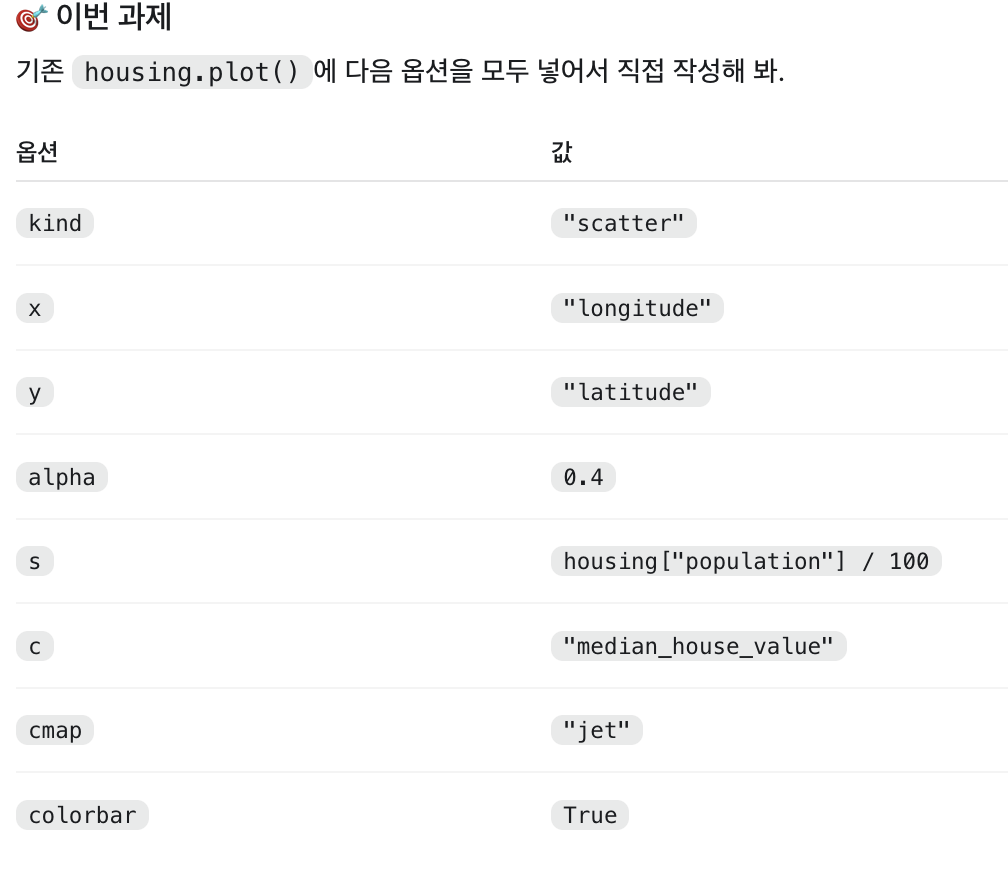

<Axes: xlabel='longitude', ylabel='latitude'>

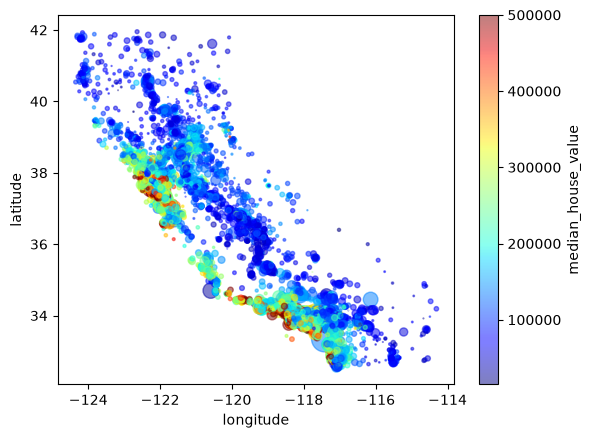

In [90]:
# 4. 주택 가격까지 표현하기 


housing.plot(kind ="scatter",
             x = "longitude",
             y = "latitude",
             alpha = 0.5,
             s = housing["population"]/100,
             c = "median_house_value",
             cmap ="jet")

> 주택 가격이 높은 구역들은 특정 지역에 집중되어있다. 
1. 주택 가격이 높은 구역 = 해안가에 집중 
- 빨강, 노랑 점 -> 캘리포니아 해안선 
2. 내륙 지역에는 상대적으로 저렴한 주택 구역이 많다. 
3. 인구가 많다고 반드시 주택 가격이 높은 건 아니다. 
    - 큰 점 중에도 파랑색이 많다. 

> 💡. 가설 1. 주택 가격은 지리적 위치와 관련이 있을 것이다. 
: 이 그래프는 위치와 가격 사이의 관계가 있을 가능성을 보여줄 뿐, 해안가에 있다는 사실이 높은 가격의 직접적인 원인이라고 증명하지는 않아.

#### 5. 상관관계 분석 
**상관계수(Correlation Coefficient)**
: 두 변수 사이의 선형적인 관계를 나타내는 값
 
 -  +1: 강한 양의 상관관계
 -  0 : 선형관계가 거의 없음 
 - -1: 강한 음의 선형관계 

In [91]:
housing.corr(numeric_only = True)["median_house_value"].sort_values(ascending = False)

median_house_value    1.000000
median_income         0.687151
income_cat            0.642256
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
Name: median_house_value, dtype: float64

🧠 여기서 중요한 개념 하나!

> 상관계수는 선형관계를 측정한다는 점을 기억하자.

예를 들어 두 변수 사이에 U자 형태의 관계가 있다면, 실제로는 뚜렷한 패턴이 존재하더라도 피어슨 상관계수는 0에 가까울 수 있어.
따라서 상관계수가 낮다고 해서 반드시 예측에 쓸모없는 변수는 아니야.

#### 6. 상관 관계 시각화
: **scatter matrix(산점도 행렬)**


<Axes: xlabel='median_income', ylabel='median_house_value'>

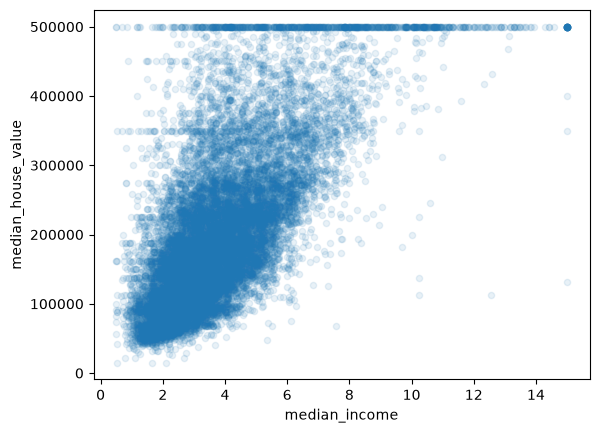

In [92]:
housing.plot(kind = "scatter",
             x = "median_income",
             y = "median_house_value",
             alpha = 0.1)

해석1. 소득과 주택 관계

: 소득이 높을수록 주택 가격도 높아지는 경향이 있지만, 반드시 그런 것은 아니다. 

해석 2. 주택 가격 500,000부근의 수평선 

: 데이터 수집 과정에서 주택 가격에 상한이 설정되어있을 가능성이 있다. 
-> **상한 절단(upper censoring)**

#### 7. 데이터 상한 확인하기 

In [93]:
#1. 
print(housing["median_house_value"].max())

#2.
count = (
    housing["median_house_value"]
    == housing["median_house_value"].max()
).sum()

print(count)

# 3. 
print(count / len(housing) )

500001.0
786
0.04760174418604651


#### 9. 새로운 특성 만들기 
: **특성 공학(Feature Engineering)**

비유) 어떤 지역에 방이 5,000개 있다고 해도, 가구가 100개인 지역과 2,000개인 지역은 주거 환경이 다르다. -> 방 개수보다 "가구당 평균 방 개수"가 유용할 수도 있다. 

🎯 이번 과제: **housing에 새로운 컬럼을 만들기**
: 가구당 방 개수 = 전체 방 개수/ 가구 수 

In [94]:
housing["rooms_per_household"] = housing["total_rooms"]/housing["households"]

housing[["total_rooms","households","rooms_per_household"]].head()

,total_rooms,households,rooms_per_household
12655,3873.0,706.0,5.485836
15502,5320.0,768.0,6.927083
2908,1618.0,300.0,5.393333
14053,1877.0,483.0,3.886128
20496,3536.0,580.0,6.096552


total_rooms만 보는 것보다 rooms_per_household가 더 유용할 것 같다. 

: total_rooms는 지역의 규모에 따라 값이 크게 달라질 수 있으므로, 가구 수로 나누어 정규화한 rooms_per_household가 주택 가격 예측에 더 유용할 것으로 예상된다

#### 9. 우리 가설 검증하기 
> total_rooms보다 rooms_per_household가 주택 가격 예측에 더 유용할 것이다. 

In [95]:
housing.corr(numeric_only = True)["median_house_value"].sort_values(ascending = False)[["total_rooms","rooms_per_household","population","households"]]

total_rooms            0.135140
rooms_per_household    0.146255
population            -0.026882
households             0.064590
Name: median_house_value, dtype: float64

#### 10. 새로운 특성 만들기 

- 상관관계의 강도를 비교할 때는 **절댓값**을 사용한다. 

- 음의 상관관계: 침실 비율이 높은 지역일수록 주택 가격이 낮은 경향이 있다. 

In [96]:
housing["bedrooms_per_room"] = housing["total_bedrooms"]/housing["total_rooms"]

housing.corr(numeric_only = True)["median_house_value"].sort_values(ascending = False)[["rooms_per_household","bedrooms_per_room"]]

rooms_per_household    0.146255
bedrooms_per_room     -0.259952
Name: median_house_value, dtype: float64

## E- 데이터 전처리 

1. 결측치 처리
2. 범주형 데이터 처리 
3. 특성 스케일링 
=> 이 과정 하나의 전처리 파이프라인으로 연결 

#### E-1. 특성과 정답 분리하기 
: 예측 값 "median_house_value"

- X (Features): 모델이 예측에 사용하는 입력 데이터
- y (Target): 모델이 예측해야 하는 정답

In [97]:
# 입력 특성 X
housing = strat_train_set.drop(columns=["median_house_value"])

# 정답 y
housing_labels = strat_train_set["median_house_value"].copy()

# 크기 확인
print(housing.shape, housing_labels.shape)

(16512, 10) (16512,)


#### E-2. 결측치 처리 
> 결측치란 데이터가 비어 있는 상태, Pandas에서는 보통 NaN으로 표시

그런데 대부분의 머신러닝 모델은 입력 데이터에 NaN이 있으면 그대로 학습할 수 없어.
그래서 결측치를 처리해야 해.
🧑‍💻 첫 번째 과제: 결측치 개수 확인하기
우선 어떤 컬럼에 결측치가 몇 개 있는지 직접 확인해 보자.

In [98]:
housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        158
population              0
households              0
median_income           0
ocean_proximity         0
income_cat              0
dtype: int64

#### E-3. SimpleImputer로 결측치 처리하기 
: **SimpleImputer**
: 결측치를 평균, 중앙값, 최빈값 등으로 채워주는 도구 

> fit()과 transform()의 차이

- fit(): 데이터에서 필요한 정보를 학습하는 단계 
- transform(): 학습한 정보를 실제 데이터에 적용하는 단계 


In [99]:
housing_num = housing.select_dtypes(include=["number"])
print(housing_num.shape, housing_num.columns)

(16512, 9) Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'income_cat'],
      dtype='str')


**[SimpleImputer]**
: 결측치를 특정 값으로 대체해주는 Scikit-learn 전처리 도구 

1. 객체 생성: 결측치 어떤 방법으로 채울지 설정 
2. fit(): Train 데이터에서 중앙값 계산 
3. transform(): 계산한 중앙값으로 결측치 채우기 

In [100]:
# 1. 객체 만들기 
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy = "median")

# 2. 학습 데이터에 적용
imputer.fit(housing_num)
print(imputer.statistics_) # 학습한 중앙값 8개 확인하기 

# 3. 실제 결측치 채우기 
housing_num_tr = imputer.transform(housing_num)
print(type(housing_num_tr), housing_num_tr.shape)
print(pd.isna(housing_num_tr).sum())

# 4. numpy array를 DataFrame으로 변환
# numpy 배열에는 값이 남아있지만, 컬럼 이름/ 행 인덱스 없음 

housing_num_df = pd.DataFrame(housing_num_tr, 
             columns=housing_num.columns, 
             index=housing_num.index)
print(housing_num_df.shape)
print(housing_num_df.isna().sum())
print(housing_num_df.head())

[-118.51      34.26      29.      2119.       433.      1164.
  408.         3.54155    3.     ]
<class 'numpy.ndarray'> (16512, 9)
0
(16512, 9)
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
income_cat            0
dtype: int64
       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
12655    -121.46     38.52                29.0       3873.0           797.0   
15502    -117.23     33.09                 7.0       5320.0           855.0   
2908     -119.04     35.37                44.0       1618.0           310.0   
14053    -117.13     32.75                24.0       1877.0           519.0   
20496    -118.70     34.28                27.0       3536.0           646.0   

       population  households  median_income  income_cat  
12655      2237.0       706.0         2.1736         2.0  
15502      2015.0       768.0    

🧠 컬럼 이름과 행 인덱스의 차이

구분 |	역할

columns |	각 값이 어떤 특성인지 알려줌 (longitude, population 등)

index 	| 각 행이 원래 어떤 데이터였는지 식별하는 데 도움을 줌

#### E-3. 범주형 데이터 처리 
목표: housing에서 ocean_proximity 컬럼만 추출해서 housing_cat에 저장하기 
-> **DataFrame 형태를 유지**해야한다. 

In [101]:
housing_cat = housing[["ocean_proximity"]]

print(housing_cat.shape)
print(type(housing_cat))
print(housing_cat.head())

(16512, 1)
<class 'pandas.DataFrame'>
      ocean_proximity
12655          INLAND
15502      NEAR OCEAN
2908           INLAND
14053      NEAR OCEAN
20496       <1H OCEAN


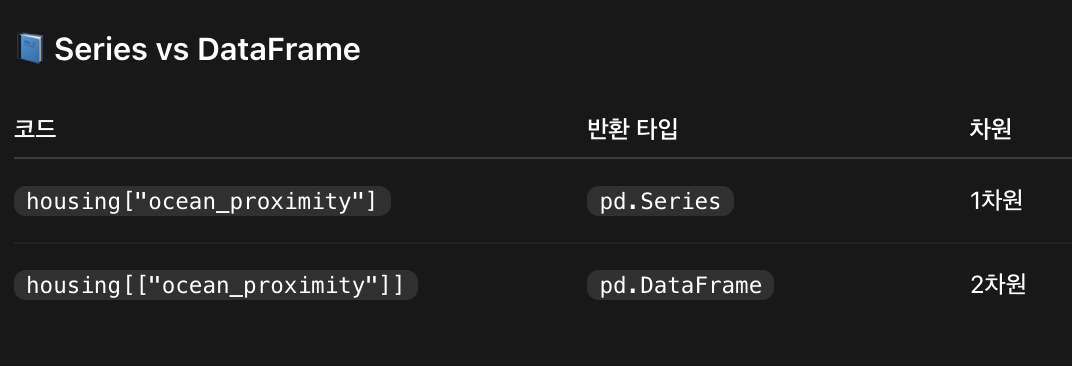

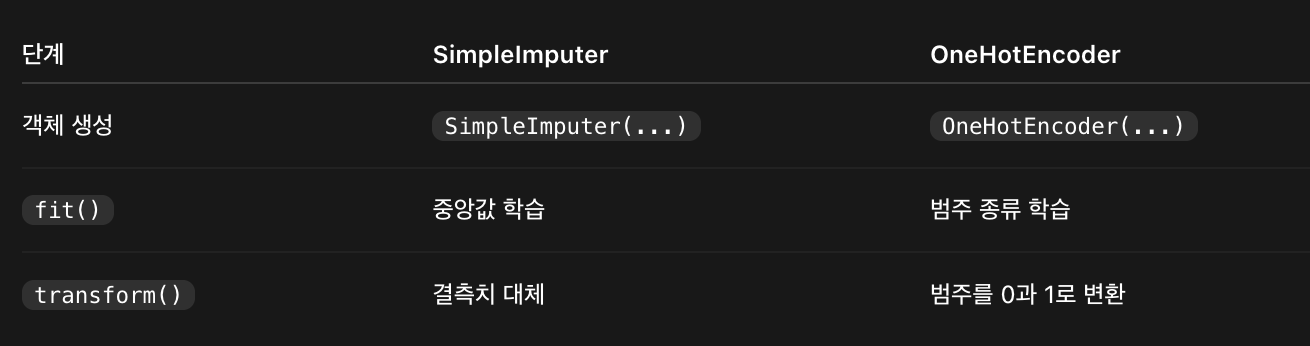

In [102]:
# 1. 객체 생성과 학습 
from sklearn.preprocessing import OneHotEncoder 

cat_encoder = OneHotEncoder()
cat_encoder.fit(housing_cat)

print(cat_encoder.categories_)

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [103]:
#2. OneHotEncoder를 이용해 실제 변환하기
housing_cat_1hot = cat_encoder.transform(housing_cat)
print(type(housing_cat_1hot), housing_cat_1hot.shape)

<class 'scipy.sparse._csr.csr_matrix'> (16512, 5)


📘 새로운 개념: 희소 행렬(Sparse Matrix)

- OneHotEncoder는 기본적으로 희소 행렬을 반환한다. 
- 희소 행렬은 대부분이 0인 데이터를 메모리에 효율적으로 저장한다. 


In [104]:
# 1. 희소행렬을 일반 넘파이 배열로 변환해보기 
housing_cat_arr = housing_cat_1hot.toarray()
print(housing_cat_arr[:5])

[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]]


1. SimpleImputer: 숫자형 데이터의 결측치 처리 
2. OneHotEncoder: 범주형 데이터를 숫자로 변환 

-> 모델을 데이터로 넣기 전에 숫자형 특성들을 크기를 비슷하게 맞추는 작업 필요


#### E-4. StandardScaler 이해하기 
: 표준화(standardization)

📘 왜 Feature Scaling이 필요할까?
population | 3000
median_income | 4.5 

-> **거리 기반 모델(KNN)에서는 이 차이가 문제가 될 수 있다**
- 인구 차이: 1,000명
- 소득 차이: 2
KNN이 유클리드 거리를 계산한다면: 거의 인구 차이만 반영 

=> 스케일링을 사용해 특성들의 크기를 비슷한 수준으로 맞추는 것 
단, 모든 모델에 필요한 건 아님 의사결정나무나 랜덤 포레스트 같은 모델은 일반적으로 스케일링에 크게 영향을 받지 않아.

In [105]:
# 1. StandardScaler 가져오기 
from sklearn.preprocessing import StandardScaler

# 2. scaler 객체 생성 
scaler = StandardScaler()

# 3. Train 데이터로 학습 
scaler.fit(housing_num_df)

# 4. 학습한 평균과 표준편차 확인하기 
print(scaler.mean_)
print(scaler.scale_)

[-119.5756353    35.63931444   28.65340359 2622.53978924  533.93943798
 1419.68737888  497.01180959    3.87588428    3.00678295]
[2.00176745e+00 2.13789807e+00 1.25744378e+01 2.13835233e+03
 4.10793820e+02 1.11562925e+03 3.75684780e+02 1.90487283e+00
 1.05456856e+00]


In [106]:
# 실제 표준화 적용하기 
## housing_num_df를 표준화하고 결과를 housing_scaled에 저장하기.

housing_scaled = scaler.transform(housing_num_df)
print(type(housing_scaled))
print(housing_scaled.shape)

print(housing_scaled.mean(axis=0))
print(housing_scaled.std(axis=0))

<class 'numpy.ndarray'>
(16512, 9)
[ 1.84434724e-15  3.60521260e-15  8.77850764e-17 -1.72127601e-17
 -1.38562719e-16 -1.93643551e-18 -1.11882940e-17 -1.11022302e-16
  1.82455257e-16]
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


#### E-5. Pipeline 이해하기 

housing_num
    ↓
SimpleImputer
    ↓
결측치 처리
    ↓
StandardScaler
    ↓
표준화된 데이터

-> 앞으로 새로운 데이터가 들어올 때마다 이 과정을 일일이 실행한다면 어떨까?
: 코드도 길어지고, 순서를 잘못 적용하거나 Train과 Test에 서로 다른 전처리를 적용할 위험도 생겨.
=> 그래서 Scikit-learn에서는 Pipeline을 제공해.
"Pipeline"은 여러 전처리 단계를 하나의 객체로 연결하는 기능이야.

In [107]:
# 1. Pipeline 객체 만들기 
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

# 2. Pipeline 사용 - 원본 숫자형 데이터 전처리 하기 
housing_prepared_num = num_pipeline.fit_transform(housing_num)

print(housing_prepared_num.shape)
print(np.isnan(housing_prepared_num).sum())
print(housing_prepared_num.mean(axis=0))
print(housing_prepared_num.std(axis=0))

(16512, 9)
0
[ 1.84434724e-15  3.60521260e-15  8.77850764e-17 -1.72127601e-17
 -1.38562719e-16 -1.93643551e-18 -1.11882940e-17 -1.11022302e-16
  1.82455257e-16]
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


housing_num (16,512행 × 8열)
          ↓
SimpleImputer
  결측치 158개 → 중앙값으로 대체
          ↓
StandardScaler
  평균 0, 표준편차 1로 변환
          ↓
housing_prepared_num
  (16,512행 × 8열)

#### E-6. ColumnTransformer

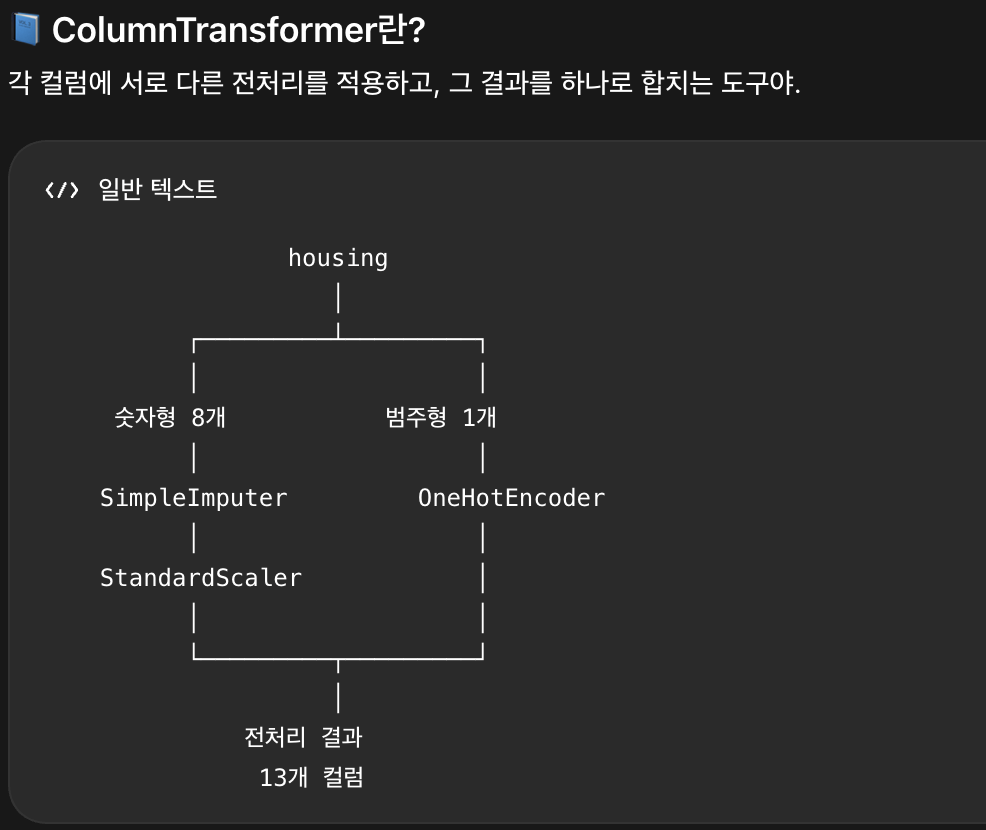


In [108]:
from sklearn.compose import ColumnTransformer
num_attribs = list(housing_num.columns)
cat_attribs = ["ocean_proximity"]

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(), cat_attribs)
])

머신러닝에서는 일반적으로 X의 행 개수와 y의 원소 개수가 일치해야 한다

우리가 사용하는 전처리 과정은 행을 삭제하지 않아.
- SimpleImputer → 결측치를 다른 값으로 대체
- StandardScaler → 기존 숫자를 표준화
- OneHotEncoder → 범주를 여러 열로 변환
따라서 각 지역에 해당하는 행은 그대로 유지되고, 열의 개수만 달라지는 거야.

#### E-10. 전체 전처리 실행하기 
> housing 전체에 전처리를 적용하고 결과를 housing_prepared에 저장하기.


In [109]:
housing_prepared = full_pipeline.fit_transform(housing)

print(type(housing_prepared))
print(housing_prepared.shape)
print(np.isnan(housing_prepared).sum())

<class 'numpy.ndarray'>
(16512, 14)
0


# F- 첫번째 머신러닝 모델 학습 
: **Linear Regression(선형회귀)**

< 선형 회귀>
1. 입력 특성들의 가중합으로 정답을 예측하는 특성 
2. 모델은 학습 데이터를 이용해 예측 오차가 작아지도록 가중치와 절편을 결정한다. 

#### F-1. 모델 객체 생성 
: scikit-learn에서 "LinearRegression"을 가져와 -> lin_reg라는 이름으로 객체 생성 

In [110]:
from sklearn.linear_model import LinearRegression 
lin_reg = LinearRegression()

#### F-2. 모델 학습 & 첫번째 집값 예측하기 
: 이 지역의 특성을 보고 집값을 예측하기 

In [111]:
lin_reg.fit(housing_prepared, housing_labels)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[-52030.9 ,-52777.75, 14298.11,...,116861.42,-23873.32,-15038.74]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.388e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](14,)","[254.53,182.73,177.38,..., 17.69, 1.58, 0. ]"


In [112]:
# 처음 다섯개 지역만 예측해보기 
# 1. 입력 데이터 5개 선택 
some_data = housing_prepared[:5]

# 2. 예측값 생성 
predictions = lin_reg.predict(some_data)

# 3. 실제 정답 확인
print(f"예측값: {predictions}")
print(f"실제값: {housing_labels[:5]}")

예측값: [ 87710.9184376  312666.78080576 148193.92872405 181973.84391033
 242269.47566914]
실제값: 12655     72100.0
15502    279600.0
2908      82700.0
14053    112500.0
20496    238300.0
Name: median_house_value, dtype: float64


: Train 데이터의 처음 5개를 예측하고 있어서, 이것만으로 모델이 새로운 데이터에서도 잘 작동한다고 판단할 수 없다. 
나중에 RMSE를 계산하고, 검증 데이터와 Test 데이터에서 성능을 평가하는 이유도 이것. 

#### F-3. RMSE로 모델 평가하기 
: Root Mean Squared Error (평균 제곱근 오차)

- 큰 오차에 상대적으로 더 큰 불이익을 주기 때문에, 집값 얘측처럼 큰 오차가 중요한 문제에서 자주 사용한다. 

🎯 이번 과제 — 전체 Train 데이터의 RMSE 계산하기

In [113]:
# 전체 데이터 예측 
housing_predictions = lin_reg.predict(housing_prepared)

# RMSE 계산하기
from sklearn.metrics import mean_squared_error
import numpy as np
mse = mean_squared_error(housing_labels, housing_predictions)
rmse = np.sqrt(mse)

print(f"Train RMSE: {rmse}")

Train RMSE: 68866.78550087014


#### F-4. 과소적합(Underfitting) 이해하기 
: 모델이 데이터에 존재하는 복잡한 패턴을 충분히 학습하지 못하는 현상을 "과소적합(underfitting)"
-> 따라서, RMSE가 69,051이라는 사실만으로 과소적합이라고 확정할 수 없다. 다른 모델이나 기준 성능과 비교해야한다. 

- 과적합: Train에서는 잘하지만 Validation에서 크게 나빠짐
- 과소적합: Train에서도 충분히 좋은 성능을 내지 못함 
- 적절한 학습: Train과 Validation 모두 성능을 내지 못함

=> 단, Train과 Validation의 오차가 비슷하다는 이유만으로 잘 학습했다고 단정할 수는 없다. 오차의 절대적인 크기도 중요하다. 

#### F-5. Decision Tree Regressor
: 선형 회귀가 특성들의 가중합으로 예측한다면, 결정 트리는 조건을 반복해서 데이터를 나누는 방식으로 예측한다. 

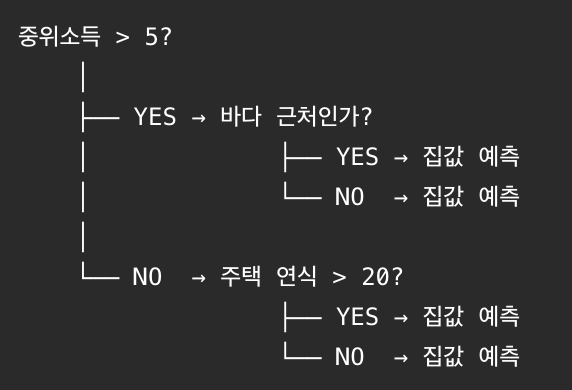

In [114]:
from sklearn.tree import DecisionTreeRegressor 

tree_reg = DecisionTreeRegressor(random_state = 42)
tree_reg.fit(housing_prepared, housing_labels)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [115]:
# 결정 트리의 RMSE 계산하기 
# Linear Regression RMSE = $69,051
tree_predictions = tree_reg.predict(housing_prepared)
tree_mse = mean_squared_error(housing_labels, tree_predictions)
tree_rmse = np.sqrt(tree_mse)
print(f"Tree RMSE: {tree_rmse}")

Tree RMSE: 0.0


1. 결정트리가 선형 회귀보다 좋은 모델인가?

2. 결정 트리는 왜 RMSE가 0일까?
    - 우리가 만든 결정 트리에는 "깊이 제한"이 없다. 
    - 결정 트리는 데이터를 계속 작은 글부으로 나누면서 학습한다. 
    - 충분히 깊게 성장하면 개별 학습 사례까지 구분 가능 = 거의 그대로 집값 재현 가능 
    != 학습 데이터를 완벽하게 맞혔다고 해서 처음 보는 데이터 잘 예측한다 아님 

=> RMSE가 0이라는 사실마능로 과적합이 확정되는 것은 아니다. 실제로 새로운 데이터에서 얼마나 잘 작동되는지 확인해야한다.

#### F-6. 교차 검증(Cross-Validation)
: 결정 트리의 일반화 성능을 확인하자. 

-> 교차 검증은 학습 데이터를 여러 부분으로 나눠서, 일부로 학습하고 나머지로 평가하는 과정을 반복하는 방법 

if) 5-fold cross validation
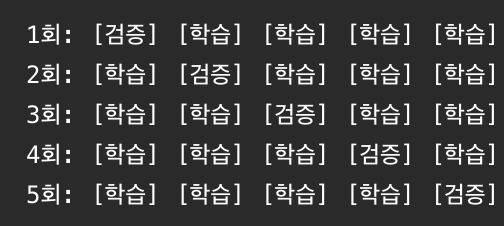


- 학습 데이터만으로도 모델이 처음 보는 사례를 얼마나 잘 예측하는지 추첮 가능 

**다만, 교차검증시, 전처리도 각 Fold의 학습 부분에서 다시 fit()해야한다**



In [116]:
from sklearn.pipeline import Pipeline
tree_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", DecisionTreeRegressor(random_state = 42))
    
])

In [117]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score

# 1. Train 데이터 준비
housing = strat_train_set.drop(columns=["median_house_value"])
housing_labels = strat_train_set["median_house_value"].copy()

# 2. 숫자형 / 범주형 컬럼 구분
num_attribs = list(housing.select_dtypes(include=["number"]).columns)
cat_attribs = ["ocean_proximity"]

# 3. 숫자형 전처리 Pipeline
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 4. 전체 전처리 Pipeline
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attribs)
])

# 5. 전처리 + 결정 트리 Pipeline
tree_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", DecisionTreeRegressor(random_state=42))
])

# 6. 5-Fold Cross-Validation
scores = cross_val_score(
    estimator=tree_pipeline,
    X=housing,
    y=housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=5,
    error_score="raise"
)

# 7. RMSE 계산
rmse_scores = -scores

print("Fold별 RMSE:", rmse_scores)
print("평균 RMSE:", rmse_scores.mean())
print("표준편차:", rmse_scores.std())

Fold별 RMSE: [69425.39505568 69016.83609433 69595.70890236 71584.39429587
 70023.97142143]
평균 RMSE: 69929.26115393642
표준편차: 888.3798051745498


: RMSE인데 왜 neg_ 가 붙을까?
-> Scikit-learn의 cross_val_score()는 점수가 클수록 좋은 방향으로 통일되어있다. 

- RMSE는 작을수록 좋아 -> 음수를 붙여서 반환 -> 실제 RMSE 확인하고 싶으면 부호 바꾸면 됨


: ValueError: Found unknown categories ['ISLAND'] in column 0 during transform

-> 즉, 첫 번째 Fold의 학습 데이터에는 ISLAND가 없었는데, 검증 데이터에는 ISLAND가 있었던 거야.


Training Error
- 모델이 학습에 사용한 데이터에서 얼마나 잘 예측하는가?

Validation Error
- 모델이 학습에 사용하지 않은 데이터에서도 잘 예측하는가?

머신러닝에서는 학습 데이터를 잘 맞히는 것보다 새로운 데이터에 일반화하는 능력이 중요해.
그래서 모델을 비교할 때 Train RMSE만 보면 안 되는 거야.

#### F-7A - Linear Regression 교차 검증 
: 결정 트리 대신, LinearRegression()을 넣을 거다

In [118]:
from sklearn.linear_model import LinearRegression 
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score 

# 1. 선형 회귀 Pipeline 만들기 
lin_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model",LinearRegression())
])

# 2. 5-Fold Cross-Validation
scores = cross_val_score(
    estimator = lin_pipeline,
    X = housing,
    y = housing_labels,
    scoring = "neg_root_mean_squared_error",
    cv = 5,
)

# 3. RMSE 계산 
lin_rmse_scores = -scores

print(f"평균 RMSE:{lin_rmse_scores.mean()}")
print("표준편차:",lin_rmse_scores.std())

평균 RMSE:69033.99269673135
표준편차: 644.644702772306


**[모델 성능 비교]**
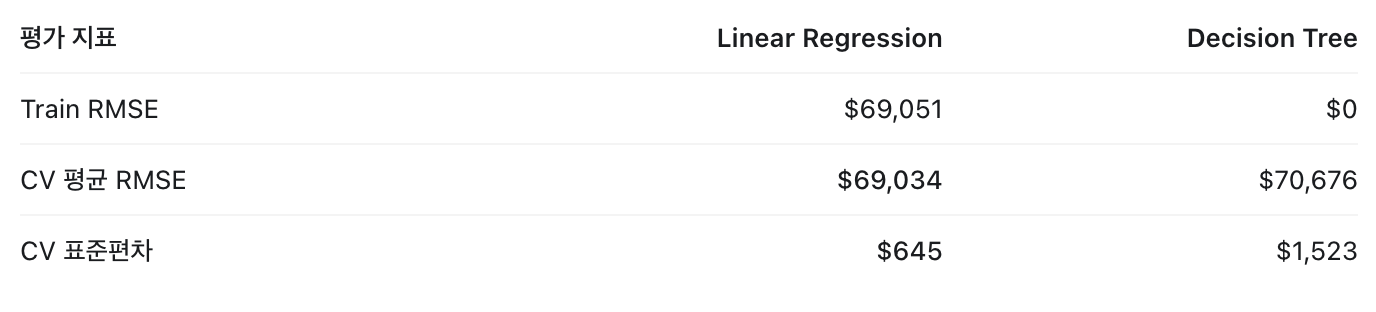

[1] LinearRegression이 더 좋은 결과를 보였다. 
[2] Decision Tree는 과적합된 것으로 보인다. 
[3] LinearRegression의 표준편차도 더 작다. 
    - 검증 Fold에 따른 RMSE 변동이 결정 트리보다 작았다는 뜻
    - 이 차이만으로 선형 회귀가 모든 데이터에서 우수하다고 확정할 수 없다. 

### F-8 Random Forest

: **RandomForest는 **여러 개의 결정 트리를 학습시키고, 각 트리의 예측값을 평균 내는 모델**이다. 

단일 결정 트리의 예측이 불안정할 수 있다는 문제를 완화하기 위해 사용하는 "앙상블(Ensemble) 기법"이다. 

In [119]:
# 지난번 pipeline을 참고해서 forest_pipeline을 만들어보자 
# 조건 1. 전처리는 기존 full_pipeline을 그대로 사용
# 조건 2. 모델은 RandomForestRegressor를 사용
# 조건 3. Pipeline으로 연결 

from sklearn.ensemble import RandomForestRegressor

forest_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", RandomForestRegressor(random_state = 42, n_estimators = 100))
])

### F-8B- Random Forest 교차 검증 
: Random Forest의 5-Fold CV 평균 RMSE와 표준편차 구하기 

조건은 다음과 같아.
- estimator=forest_pipeline
- X=housing, y=housing_labels
- scoring="neg_root_mean_squared_error"
- cv=5
- random_state=42로 수정한 Pipeline 사용

In [120]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# 1. 5-Fold Cross-Validation
forest_scores = cross_val_score(
    estimator = forest_pipeline,
    X = housing,
    y = housing_labels,
    scoring = "neg_root_mean_squared_error",
    cv = 5)

# 2. RMSE 계산
forest_rmse_scores = -forest_scores

print(f"평균 RMSE:{forest_rmse_scores.mean()}")
print(f"표준편차:{forest_rmse_scores.std()}")

평균 RMSE:49927.589898300284
표준편차:803.6496261054044


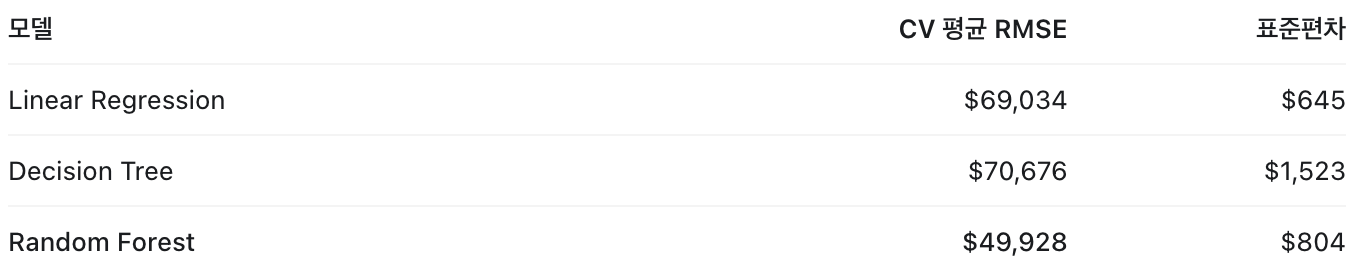

1> 단일 Decision Tree보다 RandomForest의 RMSE가 20% 감소함 

2> 현재 세 모델 중 RandomForest가 가장 좋은 검증 성능을 보이고 있다. 

3> 아직 Train 데이터 내부의 교차 검증 결과이다. 최종 Test 데이터는 계속 사용하지 않는게 맞다. 

**왜 RandomForest의 성능이 좋아졌을까?**
> Decision Tree는 한 개 트리로 예측하지만, RandomForest는 여러 트리를 학습시켜 예측값을 평균 낸다. 

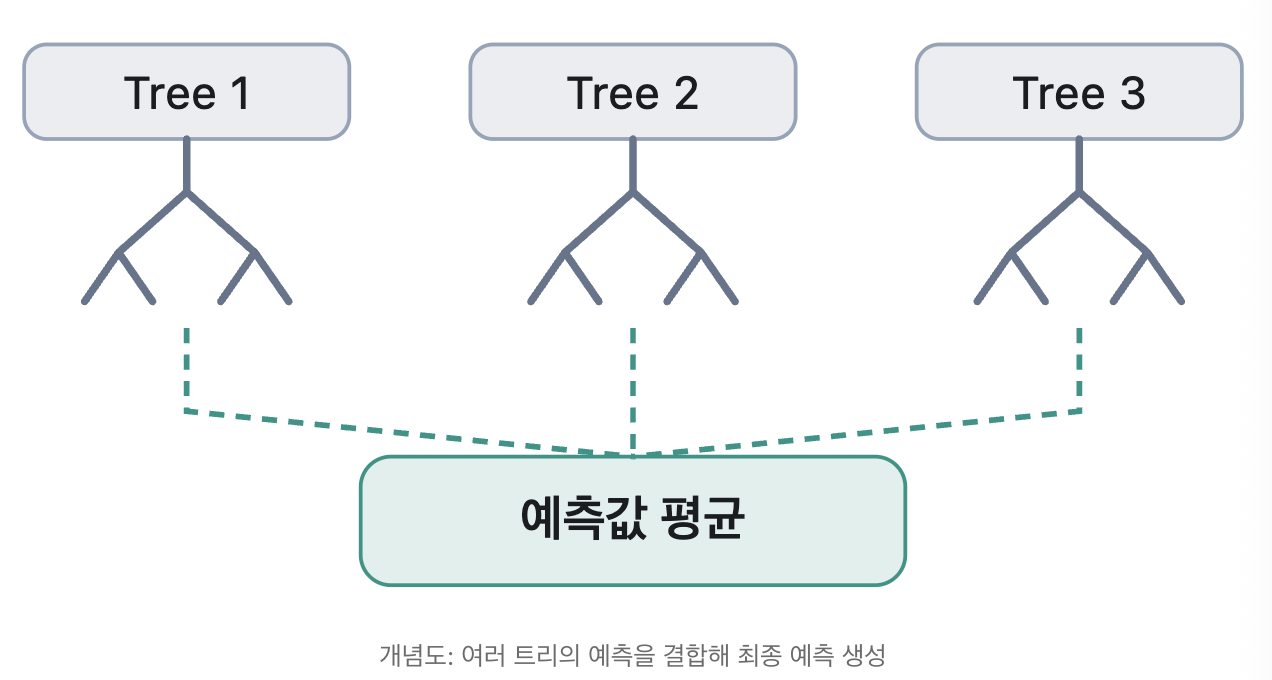

: 개별 트리가 서로 다른 실수를 한다면, 평균을 내면서 일부 오차가 상쇄될 수 있다. 특히 단일 결정 트리의 높은 분산을 줄이는데 도움이 된다. 

: 물론, 트리 100개를 사용한다고 무조건 성능이 좋아지는 것은 아니다. 트리 간 예측이 얼마나 비슷한지, 데이터 특성이 어떤지도 중요하다



## G - 하이퍼파라미터 튜닝 
: 학습 전에 설정하는 값 = **하이퍼파라미터(hyperparameter)**

> GridSearchCV를 사용해서 여러 설정을 교차 검증으로 비교, 더 좋은 조합을 찾는다. 

n_estimators=100을 n_estimators=200으로 변경하면 Random Forest의 예측 성능은 반드시 좋아질까?

- 트리를 100개에서 200개로 늘리면 성능이 개선될 수 있지만, 개선 폭이 아주 작거나 거의 없을수도 있다. 반면 학습 시간과 메모리 사용량은 증가한다.


**"GridSearchCV"**: 우리가 지정한 여러 하이퍼파라미터 조합을 교차 검증으로 평가해서 가장 좋은 조합을 찾아주는 도구

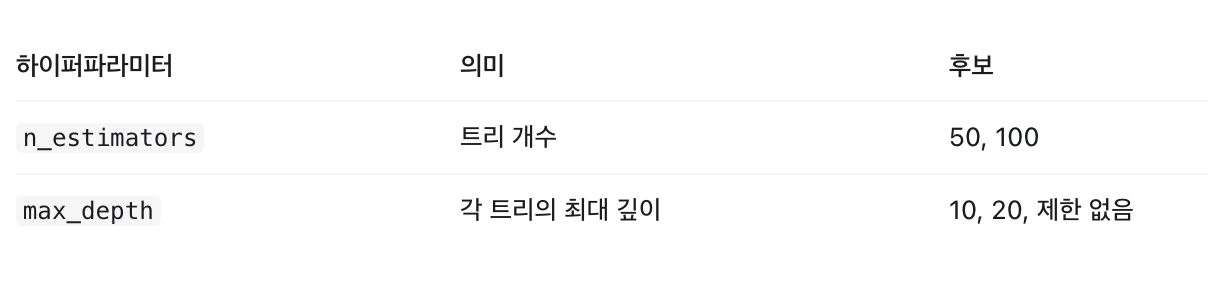


> Scikit-learn은 Pipeline 안의 파라미터를 다음과 같이 찾아간다
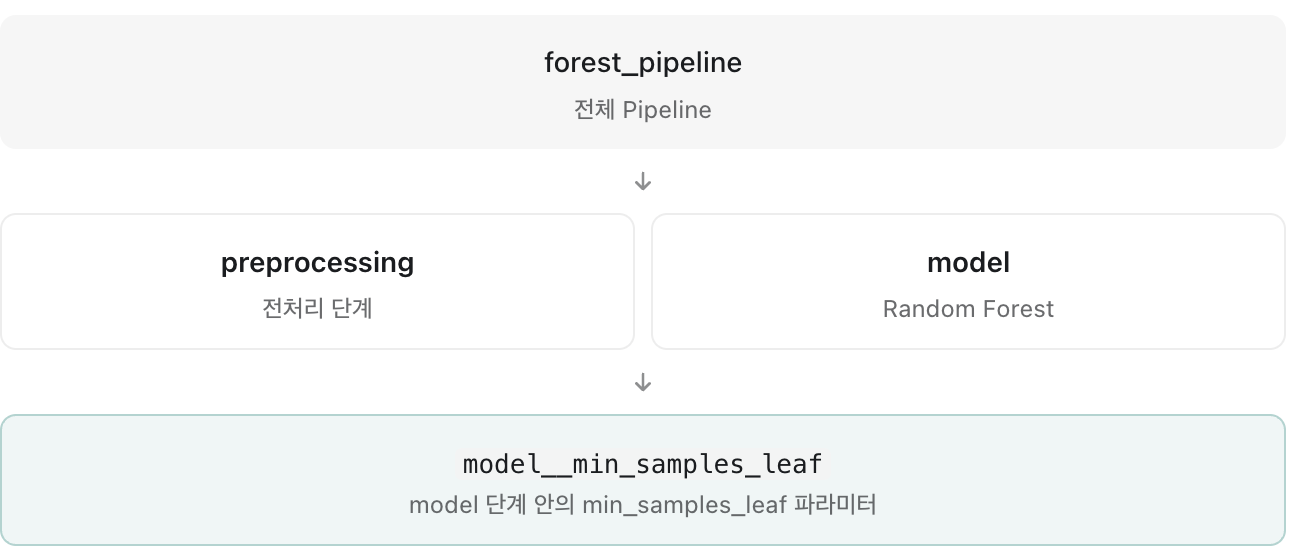

__는 어느 단계에 속한 파라미터인지 구분하는 표시 

- min_samples_leaf는 결정 트리의 마지막 노드(리프)에 필요한 최소 학습 샘플 수를 설정하는 값

In [121]:
param_grid = {
    "model__n_estimators": [50,100],
    "model__max_depth" : [10,20,None]
}

In [122]:
# GridSearchCV 객체 만들기 
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator = forest_pipeline,
    param_grid = param_grid,
    scoring = "neg_root_mean_squared_error",
    cv = 5,
    n_jobs = -1
)


- n_jobs = -1: 사용 가능한 CPU 코어를 병렬로 활용하겠다는 뜻이다. 노트북 환경에서는 메모리 사용량이 커질 수 있다. 

In [123]:
grid_search.fit(housing, housing_labels)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, 20, ...], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

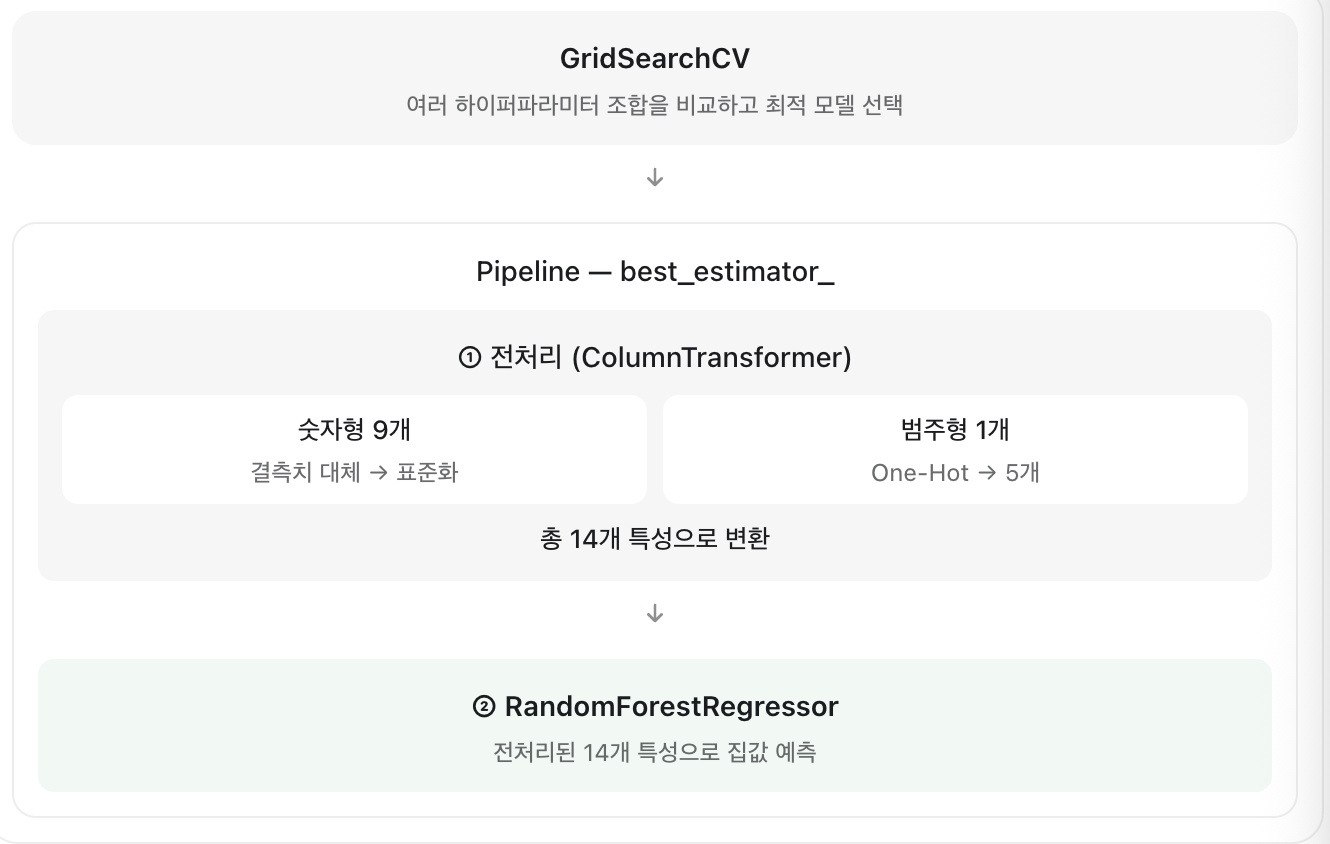

[1] GridSearchCV
 - 여러 Random Forest 설정을 비교하는 역할이야.

예를 들어 나무 개수(n_estimators)나 최대 특성 수(max_features)를 바꿔가며 교차 검증으로 성능을 비교한 거지.

[2] best_estimator_: Pipeline
- best_estimator_는 GridSearchCV가 찾은 가장 성능이 좋았던 모델 전체를 의미
- 단순, RandomForest 하나가 아니라, 전처리 -> RandomForest 연결한 Pipeline

[3] ColumnTransoformer
: 숫자형 특성 9개, 범주형 특성을 인코딩한 결과 5개가 합쳐져서 총 14개 특성

- 이전에 13개 특성을 만들었던 것과 다른 이유는 숫자형 특성이 하나 늘었기 때문일 수 있어. 현재 파이프라인이 어떤 열을 사용하는지 나중에 확인해 보면 돼. 특히 정답인 median_house_value가 포함되지 않았는지는 꼭 점검해야함

[4] RandomForestRegressor
- 마지막에 전처리된 데이터를 받아서 실제 집 값을 예측하는 모델 

- 즉, GridSearchCV가 Random Forest만 학습한 게 아니라 전처리까지 포함한 전체 Pipeline을 교차 검증했다는 점이 핵심



In [124]:
# 그림에서 알 수 없는 것, 어떤 하이퍼파라미터 선택 & RMSE 얼마인지 알 수 없다. 
# 최적 하이퍼파라미터 확인 

grid_search.best_params_

{'model__max_depth': None, 'model__n_estimators': 100}

In [125]:
# 최적 모델의 RMSE 확인 
grid_search.best_score_

np.float64(-49927.589898300284)

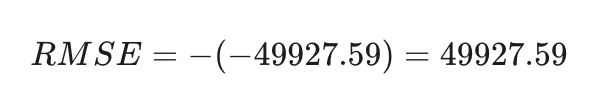

In [126]:
# 실험 설정 검증 
print("CV:", grid_search.cv)
print("Best score:",grid_search.best_score_)

CV: 5
Best score: -49927.589898300284


##### G-2. 데이터 누수 확인 
: 숫자형 특성이 9개로 표시???

원래 California Housing 데이터에서는 숫자형 입력 특성이 8개이고, median_house_value는 우리가 예측해야 하는 정답
- 만약 정답이 입력에 들어갔다면??? 신뢰할 수 있을까?

In [127]:
print("housing 컬럼:", housing.columns.tolist())
print("숫자형 컬럼:", num_attribs)
print("정답 포함 여부:", "median_house_value" in housing.columns)

housing 컬럼: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity', 'income_cat']
숫자형 컬럼: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'income_cat']
정답 포함 여부: False


문제) "income_cat"

- 앞에서 **계층적 샘플링(Stratified Sampling)**을 하면서 임시로 만들었던 변수 

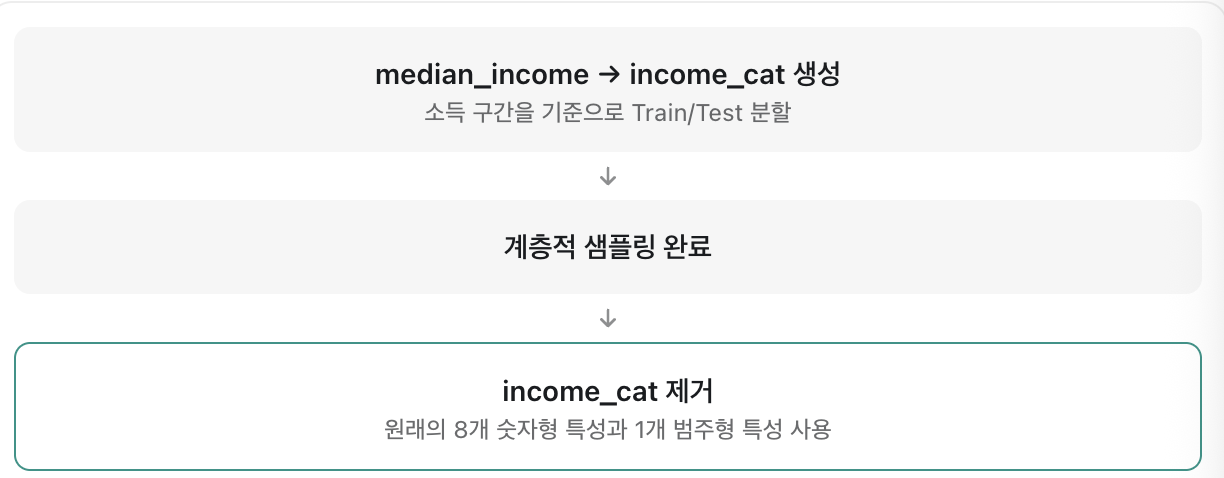

- 정답을 직접 노출하는 타깃 누수는 아니지만, 앞서 계산된 RMSE를 다시 계산해야한다

In [128]:
# 입력 특성에서 임시 컬럼과 정답 제거
housing = strat_train_set.drop(
    columns=["median_house_value", "income_cat"]
)

housing_labels = strat_train_set["median_house_value"].copy()

# 숫자형 특성 목록 다시 생성
num_attribs = list(
    housing.select_dtypes(include=["number"]).columns
)

print("housing shape:", housing.shape)
print("숫자형 특성 수:", len(num_attribs))
print("income_cat 포함 여부:", "income_cat" in housing.columns)

housing shape: (16512, 9)
숫자형 특성 수: 8
income_cat 포함 여부: False


#### G-3. 전처리 Pipeline 다시 만들기 

우리는 housing과 num_attribs를 수정했지만, 기존 full_pipeline은 예전 숫자형 컬럼 9개를 기억하고 있을 수 있어.

따라서 전처리 Pipeline을 다시 정의해야 해

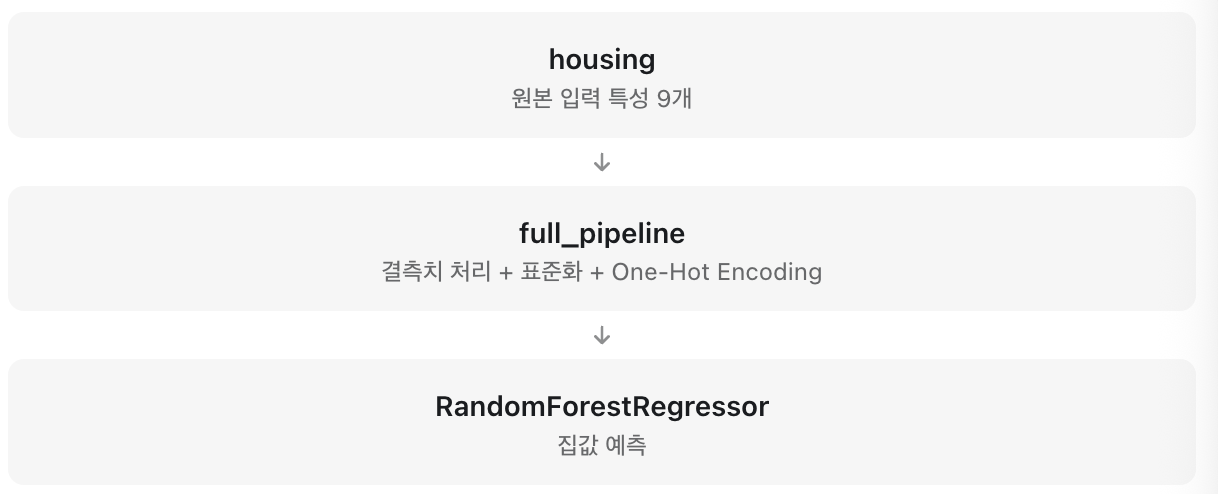

In [129]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_attribs = ["ocean_proximity"]

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_attribs)
])

print("숫자형 특성:", num_attribs)
print("범주형 특성:", cat_attribs)

숫자형 특성: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
범주형 특성: ['ocean_proximity']


[왜 다시 만들어야하나]

- ColumnTransformer을 다시 만들 때 전달한 컬럼 목록은 객체 안에서 저장된다. 따라서 외부 변수인 num_attribs를 새로 정의했다고 해서 기존 객체의 설정이 자동으로 바뀌는 것은 아니다. 

- 이전에 학습했던 grid_search도 자동으로 업데이트 되지 않는다. 

In [130]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

forest_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", RandomForestRegressor(random_state=42, n_estimators=100)) 
])

#### G-3. GridSearchCV 다시 연결하기

In [131]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [10, 20, None]
}

grid_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

In [132]:
grid_search.fit(housing, housing_labels)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, 20, ...], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [133]:
print(
    forest_pipeline.named_steps["preprocessing"].transformers
)

[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']), ('cat', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity'])]


In [134]:
print(grid_search.estimator.named_steps["preprocessing"].transformers)

[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']), ('cat', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity'])]


In [135]:
grid_search.set_params(estimator=forest_pipeline)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, 20, ...], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [136]:
print(
    grid_search.estimator.named_steps["preprocessing"].transformers
)

[('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']), ('cat', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity'])]


In [137]:
grid_search.fit(housing, housing_labels)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, 20, ...], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [138]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)

results[[
    "param_model__max_depth",
    "param_model__n_estimators",
    "mean_test_score",
    "rank_test_score"
]]

,param_model__max_depth,param_model__n_estimators,mean_test_score,rank_test_score
0,10,50,-54307.954610,6
1,10,100,-54074.238205,5
2,20,50,-50333.203075,4
3,20,100,-49947.028506,2
4,None,50,-50325.676705,3
5,None,100,-49941.180890,1


In [139]:
final_model = grid_search.best_estimator_

print(type(final_model))

<class 'sklearn.pipeline.Pipeline'>


In [140]:
grid_search.best_params_     # 최적 하이퍼파라미터
grid_search.best_score_      # 최적 교차 검증 점수
grid_search.best_estimator_  # 학습이 완료된 최적 모델

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throug

### H-1. 테스트셋 준비 

전체 데이터 20,640개를 나눴다, 훈련 데이터 80%, 테스트 데이터 20%로. 

- 지금까지 테스트셋은 모델 학습이나 하이퍼파라미터 선택에 사용하지 않았다. 최종 성능을 평가하기 위해 사용 

In [141]:
X_test = strat_test_set.drop(
    columns = ["median_house_value","income_cat"]
)
y_test = strat_test_set["median_house_value"].copy()

print(X_test.shape)
print(y_test.shape)

(4128, 9)
(4128,)


### H-2. 최종 예측하기 
: 테스트셋의 주택 가격 예측하기 

In [142]:
final_predictions = final_model.predict(X_test)

print(final_predictions[:5])
print(final_predictions.shape)
print(y_test.iloc[:5].values)

[483020.6  221708.09 205706.   170623.   212497.  ]
(4128,)
[500001. 162500. 204600. 159700. 184000.]


y_test가 pandas Series일때, .values는 NumPy 배열로 추출한다. 

즉, 인덱스 값 없이 값만 배열로 가져온다. 



### H-3. 최종 RMSE 계산
: 최종 모델의 성능을 숫자로 확인하자 
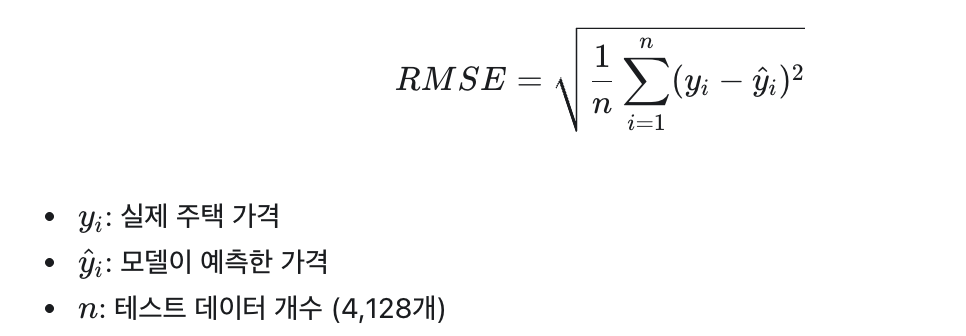
>예측값과 실제값이 완전히 같지 않더라도 모델이 좋은 모델일 수 있을까? 왜 그렇게 생각해?


In [143]:
from sklearn.metrics import root_mean_squared_error

final_rmse = root_mean_squared_error(y_test,final_predictions)

print(f"Final Test RMSE: {final_rmse: ,.2f}")

Final Test RMSE:  47,197.67


### H-4. 모델 성능 해석하기 
> 훈련 RMSE는 $18,000인데 교차 검증 RMSE가 $49,941이라면, 이 모델에는 어떤 문제가 있을 가능성이 높을까?

**[과적합(overfitting]**
- 우리가 가정한 결과
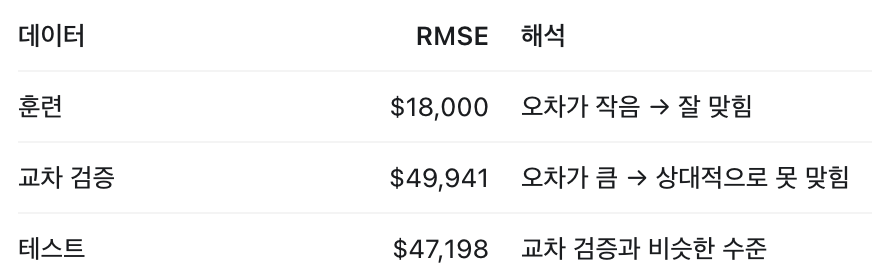

: **RMSES는 낮을 수록 좋다**

**[과적합과 과소적합의 비교]**
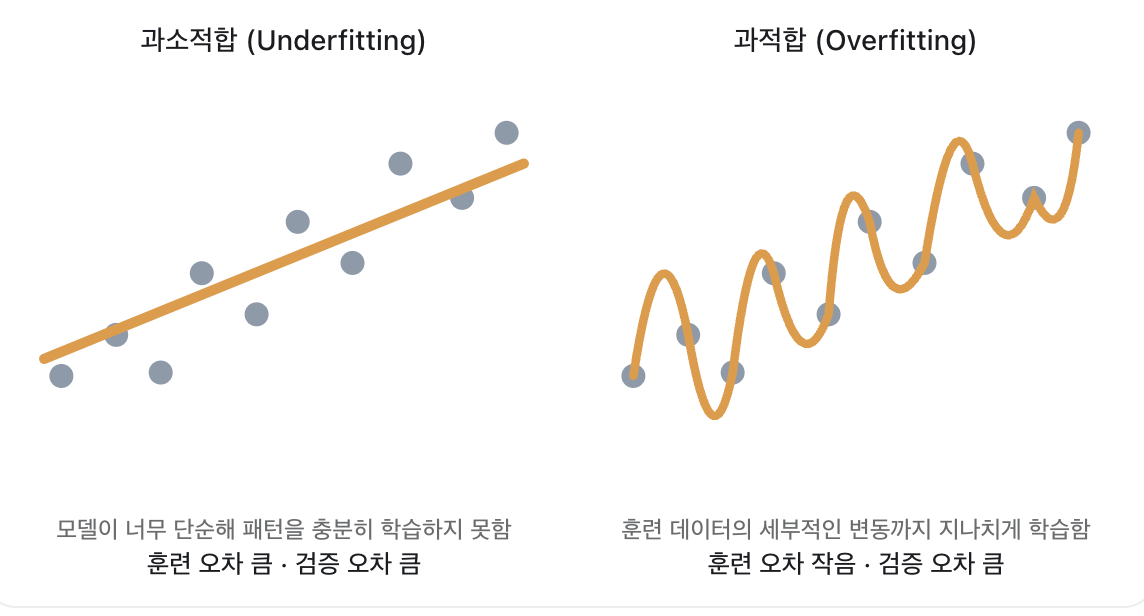

### H-05. 실제 훈련 RMSE 확인하기 

In [144]:
train_predictions = final_model.predict(housing)

train_rmse = root_mean_squared_error(housing_labels, train_predictions)

print(f"Train RMSE: {train_rmse: ,.2f}")
print(f"Final Test RMSE: {final_rmse: ,.2f}")

Train RMSE:  18,342.37
Final Test RMSE:  47,197.67


결과에서 두 가지를 구분 

1. 과적합의 징후가 있다. 
    - 훈련 데이터에서는 오차가 작지만, 처음 보는 데이터에서 오차가 커졌다. 
    - 모델이 훈련 데이터의 세부적인 패턴까지 지나치게 학습했을 가능성이 있다. 

2. 모델이 실패했다는 뜻은 아니다. 
    - 교차 검증 RMSE는 약 $49,941, 테스트 RMSE는 약 $47,198
    - 서로 다른 평가 데이터에서 비슷한 성능을 보여, 일반화 성능 자체는 비교적 일관되게 관찰됨. 
    - 훈련 성능과의 격차는 개선할 여지가 있다. 
    
=> **최종 테스트셋을 보고 다시 하이퍼파라미터를 선택하면 안된다. 추가 개선 실험을 한다면 훈련 데이터와 교차 검증을 이용해야함**

### H-6. 과적합을 줄이는 방법 생각하기 

max_depth = None

- 트리 깊이에 명시적인 제한을 두지 않는다. 

> 과적합을 줄이고 싶다면, max_depth를 줄이는게 좋을까, 늘리는게 좋을가?


: 줄이는 게 좋다. 과적합은 해당 데이터의 패턴을 너무 잘 익혀서 새로 보는 데이터에 대해 맞춰지지 않은 것이므로, max_dept를 줄여 트리들이 패턴을 덜 익히게하기 때문이다

### 마지막 평가: MAE

**MAE(Mean Absolute Error)**
- 예측값과 실제값 사이의 절대오차를 평균한 값
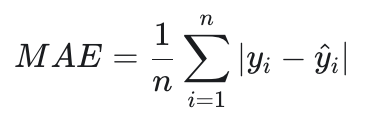

- RMSE는 큰 오차에 더 민감하지만, MAE는 각 오차의 크기를 그대로 평균한다

In [145]:
from sklearn.metrics import mean_absolute_error

final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

print(f"Final Test MAE: ${final_mae:,.2f}")
print(f"Final Test RMSE: ${final_rmse:,.2f}")

Final Test MAE: $30,929.48
Final Test RMSE: $47,197.67
